In [1]:
import pandas as pd
import numpy as np

import tensorflow as tf
import keras
import torch

You can view the dataset on kaggle  https://www.kaggle.com/datasets/omkargurav/face-mask-dataset

In [2]:
!kaggle datasets download -d omkargurav/face-mask-dataset

Dataset URL: https://www.kaggle.com/datasets/omkargurav/face-mask-dataset
License(s): unknown
100% 163M/163M [00:01<00:00, 113MB/s] 



In [3]:
!mkdir face-mask-dataset
!unzip /content/face-mask-dataset.zip -d face-mask-dataset

Streaming output truncated to the last 5000 lines.
  inflating: face-mask-dataset/data/with_mask/with_mask_3297.jpg  
  inflating: face-mask-dataset/data/with_mask/with_mask_3298.jpg  
  inflating: face-mask-dataset/data/with_mask/with_mask_3299.jpg  
  inflating: face-mask-dataset/data/with_mask/with_mask_33.jpg  
  inflating: face-mask-dataset/data/with_mask/with_mask_330.jpg  
  inflating: face-mask-dataset/data/with_mask/with_mask_3300.jpg  
  inflating: face-mask-dataset/data/with_mask/with_mask_3301.jpg  
  inflating: face-mask-dataset/data/with_mask/with_mask_3302.jpg  
  inflating: face-mask-dataset/data/with_mask/with_mask_3303.jpg  
  inflating: face-mask-dataset/data/with_mask/with_mask_3304.jpg  
  inflating: face-mask-dataset/data/with_mask/with_mask_3305.jpg  
  inflating: face-mask-dataset/data/with_mask/with_mask_3306.jpg  
  inflating: face-mask-dataset/data/with_mask/with_mask_3307.jpg  
  inflating: face-mask-dataset/data/with_mask/with_mask_3308.jpg  
  inflating: f

In [4]:
train_ds=keras.utils.image_dataset_from_directory(
    directory='/content/face-mask-dataset/data',
    label_mode='int',
    image_size=(256,256),
    batch_size=32,
    validation_split=0.3,
    subset='training',
    seed=42
)

Found 7553 files belonging to 2 classes.
Using 5288 files for training.


In [5]:
val_ds=keras.utils.image_dataset_from_directory(
    directory='/content/face-mask-dataset/data',
    batch_size=32,
    image_size=(256,256),
    seed=42,
    validation_split=0.3,
    label_mode='int',
    subset='validation'

)

Found 7553 files belonging to 2 classes.
Using 2265 files for validation.


In [6]:
val_total_batch=tf.data.experimental.cardinality(val_ds)
test_size=val_total_batch//2

In [7]:
test_ds=val_ds.take(test_size)
val_ds=val_ds.skip(test_size)

In [8]:
# which means trasforming our pixel values from 0-255 to 0-1
def process(image,label):
  image = tf.cast(image/255. ,tf.float32)
  return image,label

train_ds = train_ds.map(process)
test_ds = test_ds.map(process)
val_ds=val_ds.map(process)

In [9]:
from keras.layers import Dense,Dropout,BatchNormalization,Conv2D,MaxPooling2D,Flatten
from keras.models import  Sequential
from keras.optimizers import Adam
from keras.callbacks import EarlyStopping

Performing data augmentation to increase the amount of images

In [10]:
from keras import layers

data_aug = keras.Sequential([
    keras.Input(shape=(256, 256, 3)),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

In [11]:
model=Sequential()

In [12]:

model.add(keras.Input(shape=(256, 256, 3)))
model.add(data_aug)
model.add(Conv2D(32,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(strides=2,pool_size=(2,2),padding='valid'))

model.add(Conv2D(64,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(strides=2,pool_size=(2,2),padding='valid'))

model.add(Conv2D(128,kernel_size=(3,3),padding='valid',activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(strides=2,pool_size=(2,2),padding='valid'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))
model.add(Dropout(0.1))

model.add(Dense(64,activation='relu'))
model.add(Dropout(0.1))

model.add(Dense(32,activation='relu'))
model.add(Dropout(0.1))

model.add(Dense(1,activation='sigmoid'))

In [13]:
model.compile(optimizer=Adam(learning_rate=0.001),metrics=['accuracy'],loss='binary_crossentropy')

In [14]:
history=model.fit(train_ds,epochs=10,validation_data=val_ds,callbacks=[EarlyStopping(patience=5,restore_best_weights=True,monitor='val_loss')])

Epoch 1/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 39s 174ms/step - accuracy: 0.7825 - loss: 2.1303 - val_accuracy: 0.6812 - val_loss: 1.7151
Epoch 2/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 29s 173ms/step - accuracy: 0.8220 - loss: 0.7710 - val_accuracy: 0.8201 - val_loss: 0.8424
Epoch 3/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 28s 171ms/step - accuracy: 0.8432 - loss: 0.5043 - val_accuracy: 0.8585 - val_loss: 0.3878
Epoch 4/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 28s 169ms/step - accuracy: 0.8550 - loss: 0.3858 - val_accuracy: 0.7808 - val_loss: 0.7846
Epoch 5/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 44s 188ms/step - accuracy: 0.8655 - loss: 0.3442 - val_accuracy: 0.8996 - val_loss: 0.2302
Epoch 6/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 29s 172ms/step - accuracy: 0.8890 - loss: 0.2813 - val_accuracy: 0.8952 - val_loss: 0.2631
Epoch 7/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 31s 185ms/step - accuracy: 0.8930 - loss: 0.2642 - val_accuracy: 0.9074 - val_loss: 0.2405
Epoch 8/10
166/166 ━━━━━━━━━━━━━━━━━━━━ 28s 171ms/step - accuracy: 0.9026 - loss: 0

In [15]:
test_loss,test_accu=model.evaluate(test_ds)
print("Accuracy: ",test_accu)
print("Loss: ",test_loss)

35/35 ━━━━━━━━━━━━━━━━━━━━ 2s 46ms/step - accuracy: 0.8786 - loss: 0.2737
Accuracy:  0.8785714507102966
Loss:  0.27372705936431885


Checking the performnace of the model

In [16]:
import matplotlib.pyplot as plt

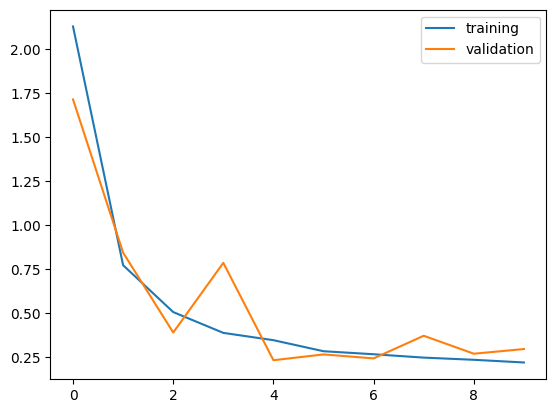

In [17]:
plt.plot(history.history['loss'],label='training')
plt.plot(history.history['val_loss'],label='validation')
plt.legend()
plt.show()

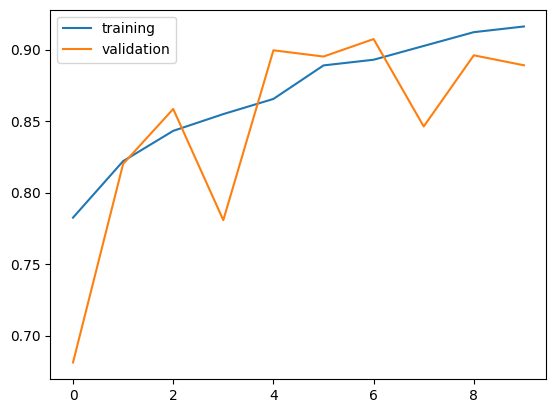

In [18]:
plt.plot(history.history['accuracy'],label='training')
plt.plot(history.history['val_accuracy'],label='validation')
plt.legend()
plt.show()

In [19]:
# Re-instantiate a temporary dataset structure to read the class names before any mappings
temp_ds = keras.utils.image_dataset_from_directory(
    directory='/content/face-mask-dataset/data',
    image_size=(256,256),
    batch_size=32,
    seed=42
)

for i, class_name in enumerate(temp_ds.class_names):
    print(f"Class Label {i} corresponds to: {class_name}")

Found 7553 files belonging to 2 classes.
Class Label 0 corresponds to: with_mask
Class Label 1 corresponds to: without_mask


In [20]:
import cv2

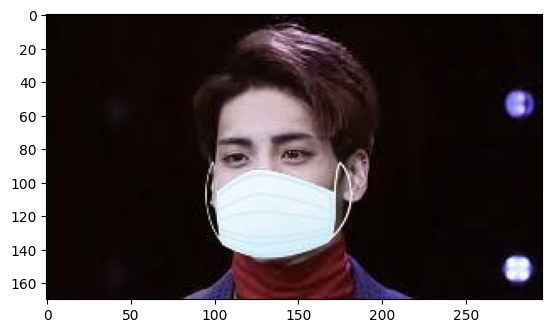

In [21]:
test_image=plt.imread('/content/face-mask-dataset/data/with_mask/with_mask_1022.jpg')
plt.imshow(test_image)

In [22]:
test_image_resize=cv2.resize(test_image,(256,256))
test_image_reshape=test_image_resize.reshape(1,256,256,3)/255.0
model.predict(test_image_reshape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step


array([[0.17340602]], dtype=float32)

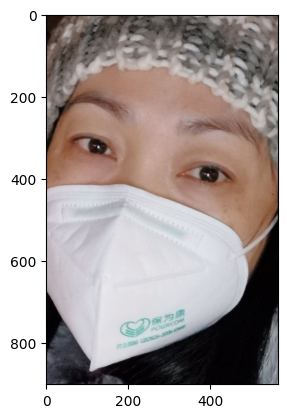

In [23]:
test_image=plt.imread('/content/face-mask-dataset/data/with_mask/with_mask_101.jpg')
plt.imshow(test_image)

In [24]:
test_image_resize=cv2.resize(test_image,(256,256))
test_image_reshape=test_image_resize.reshape(1,256,256,3)/255.0
model.predict(test_image_reshape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


array([[0.00092555]], dtype=float32)

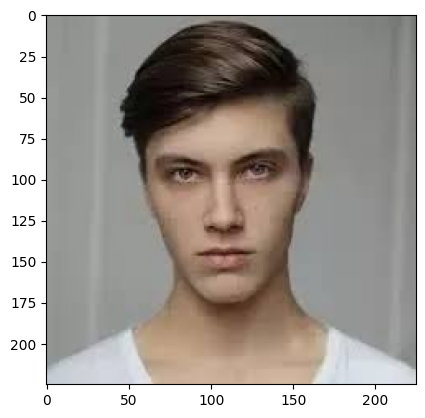

In [25]:
test_image=plt.imread('/content/face-mask-dataset/data/without_mask/without_mask_1011.jpg')
plt.imshow(test_image)

In [26]:
test_image_resize=cv2.resize(test_image,(256,256))
test_image_reshape=test_image_resize.reshape(1,256,256,3)/255.0
model.predict(test_image_reshape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step


array([[0.99924505]], dtype=float32)

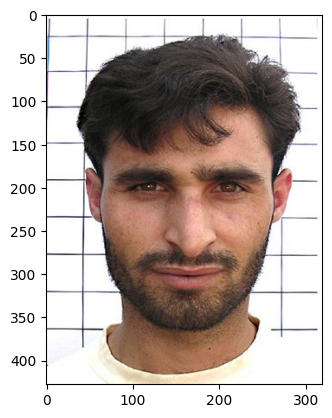

In [27]:
test_image=plt.imread('/content/face-mask-dataset/data/without_mask/without_mask_1012.jpg')
plt.imshow(test_image)

In [28]:
test_image_resize=cv2.resize(test_image,(256,256))
test_image_reshape=test_image_resize.reshape(1,256,256,3)/255.0
model.predict(test_image_reshape)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


array([[0.99959224]], dtype=float32)

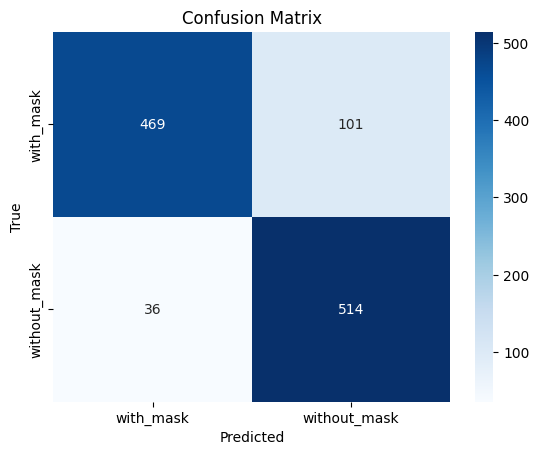

              precision    recall  f1-score   support

   with_mask       0.93      0.82      0.87       570
without_mask       0.84      0.93      0.88       550

    accuracy                           0.88      1120
   macro avg       0.88      0.88      0.88      1120
weighted avg       0.88      0.88      0.88      1120



In [29]:
import numpy as np
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Collect true labels and predictions
y_true, y_pred = [], []

for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    classes = (preds > 0.5).astype(int).flatten()
    y_true.extend(labels.numpy())
    y_pred.extend(classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 2. Confusion matrix
cm = confusion_matrix(y_true, y_pred)

# 3. Plot heatmap (simple style)
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues",
            xticklabels=["with_mask", "without_mask"],
            yticklabels=["with_mask", "without_mask"])
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

# 4. Classification report
print(classification_report(y_true, y_pred, target_names=["with_mask", "without_mask"]))


In [30]:
import os

data_dir = "/content/face-mask-dataset/data"
classes = ["with_mask", "without_mask"]

for cls in classes:
    folder_path = os.path.join(data_dir, cls)
    count = len(os.listdir(folder_path))
    print(f"{cls}: {count} images")


with_mask: 3725 images
without_mask: 3828 images


In [32]:
model.save("mask_model.keras")
from google.colab import files
files.download("mask_model.keras")
print("Model successfully saved")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Model successfully saved
